(dro_portfolio_uncertain_moment:title)=
# Robust Portfolio under Moment Uncertainty

In this example, we will use RSOME to solve the portfolio problem discussed in {cite:ps}`Delage2010distributionally`, which is formulated as the following distributionally robust model

```{math}
\begin{aligned}
\min~&\sup\limits_{\mathbb{P}\in\mathcal{F}}\mathbb{E}_{\mathbb{P}}\left[
\alpha + \frac{1}{\epsilon}\max\left\{-\tilde{\pmb{\xi}}^{\top}\pmb{x} - \alpha, 0\right\}
\right] \\
\text{s.t.}~&\sum\limits_{i=1}^nx_i = 1 \\
&\pmb{x}\in\mathbb{R}_+^n,
\end{aligned}
```

where $\tilde{\pmb{\xi}}\in\mathbb{R}^n$ is a random vector representing the uncertain returns of $n$ stocks. The objective of the model is to minimize the conditional value-at-risk (CVaR) of the investment return under the worst-case distribution $\pmb{P}$ over the ambiguity set $\mathcal{F}$, defined as below,

```{math}
\mathcal{F}=\left\{
\mathbb{P}\in\mathcal{P}_0(\mathbb{R}^n)\left|
\begin{array}{l}
\tilde{\pmb{\xi}}\sim \mathbb{P} \\
\left(\mathbb{E}_{\mathbb{P}}[\tilde{\pmb{\xi}}] - \pmb{\mu}\right)^{\top}\pmb{\Sigma}^{-1}\left(\mathbb{E}_{\mathbb{P}}[\tilde{\pmb{\xi}}] - \pmb{\mu}\right) \leq \gamma_1 \\
\mathbb{E}_{\mathbb{P}}\left[\left(\tilde{\pmb{\xi}} - \pmb{\mu}\right)\left(\tilde{\pmb{\xi}} - \pmb{\mu}\right)^{\top}\right] \preceq \gamma_2 \pmb{\Sigma}
\end{array}
\right.
\right\},
```

where $\pmb{\mu}$ and $\pmb{\Sigma}$ are the mean and covariance matrix, respectively, of the random return vector $\tilde{\pmb{\xi}}$, estimated based on the [stocks.csv](stocks.csv) dataset using the `estimate_return()` function imported from the [preprocessing.py](preprocessing.py) module. Details of the data preprocessing procedure can be found at [Mosek Portfolio Optimization Cookbook](https://docs.mosek.com/portfolio-cookbook/inputdata.html).

In [1]:
import pandas as pd
from preprocessing import estimate_return

data = pd.read_csv('stocks.csv').set_index('Date')

mean, cov = estimate_return(data)
μ, Σ = mean.values, cov.values

In the subsequent numerical experiments, the conservatism parameters $\gamma_1=0.25$ and $\gamma_2=1.50$, and the confidence level for calculating the CVaR is $1-\epsilon=0.95$.

In [2]:
γ1, γ2 = 0.25, 1.50
ε = 0.05

According to {cite:ps}`Delage2010distributionally`, the distributionally robust model is equivalent to the following convex optimization problem

```{math}
\begin{aligned}
\min~&r + t \\
\text{s.t. }&\left(
\begin{array}{cc}
\pmb{Q} & \pmb{q}/2 + (1/\epsilon)\pmb{x}/2 \\
\pmb{q}^{\top}/2 + (1/\epsilon)\pmb{x}^{\top}/2 & r + \alpha(1-\epsilon)/\epsilon
\end{array}
\right) \succeq 0 \\
&\left(
\begin{array}{cc}
\pmb{Q} & \pmb{q}/2 \\
\pmb{q}^{\top}/2 & r -\alpha
\end{array}
\right) \succeq 0 \\
&t \geq \left(\gamma_2\pmb{\Sigma} + \pmb{\mu}\pmb{\mu}^{\top}\right)\cdot \pmb{Q} + \pmb{\mu}^{\top}\pmb{q} + \sqrt{\gamma_1}\left\|\pmb{\Sigma}^{1/2}(\pmb{q}+2\pmb{Q\mu})\right\| \\
&\sum\limits_{i=1}^nx_i = 1 \\
&\pmb{x}\in\mathbb{R}_+^n, ~\alpha \in \mathbb{R}, ~\pmb{Q}\in\mathbb{S}^n, ~\pmb{q}\in\mathbb{R}^n, r \in\mathbb{R}, ~t\in\mathbb{R}, ~s\in\mathbb{R}
\end{aligned}
```

The convex optimization problem is then implemented using RSOME with the code below.

In [3]:
from rsome import ro
import rsome as rso
from scipy.linalg import sqrtm

model = ro.Model()

n = len(μ)
x = model.dvar(n)
α = model.dvar()
Q = model.dvar((n, n))
q = model.dvar(n)
r = model.dvar()
t = model.dvar()
s = model.dvar()

model.min(r + t)
model.st(rso.schur(Q, q*0.5 + (1/ε)*x*0.5, r+(1-ε)/ε*α))
model.st(rso.schur(Q, q*0.5, r-α))
model.st(
    t >= γ2*(Σ*Q).sum()
    + μ@Q@μ + μ@q
    + γ1**0.5*rso.norm(sqrtm(Σ)@(q + 2*Q@μ))
)
model.st(x >= 0, x.sum() == 1)

model.solve()

Being solved by Clarabel 0.11.1...
Solution status: Solved
Running time: 0.0157s


The objective value of the convex optimization problem is attained as below.

In [4]:
print(f'Objective value: {model.get():.4f}')

Objective value: 0.9333


In addition, we can also formulate the portfolio optimization problem as an RSOME `dro` model, where the ambiguity set is written as the following lifted version,

```{math}
\mathcal{G} = \left\{
\mathbb{P}\in\mathcal{P}_0\left(\mathbb{R}^n\times \mathbb{S}^n\right)\left|
\begin{array}{l}
\left(\tilde{\pmb{\xi}}, \tilde{\pmb{U}}\right)\sim\mathbb{P} \\
\mathbb{P}\left[
\left(
\begin{array}{c}
\tilde{\pmb{U}} & \tilde{\pmb{\xi}} - \pmb{\mu} \\
\tilde{\pmb{\xi}}^{\top} - \pmb{\mu}^{\top} & 1
\end{array}
\right) \succeq 0
\right] = 1 \\
\left(\mathbb{E}_{\mathbb{P}}[\tilde{\pmb{\xi}}] - \pmb{\mu}\right)^{\top}\pmb{\Sigma}^{-1}\left(\mathbb{E}_{\mathbb{P}}[\tilde{\pmb{\xi}}] - \pmb{\mu}\right) \leq \gamma_1 \\
\mathbb{E}_{\mathbb{P}}\left[\tilde{\pmb{U}}\right] = \gamma_2 \pmb{\Sigma}
\end{array}
\right.
\right\}.
```

In the lifted ambiguity set $\mathcal{G}$, $\tilde{\pmb{U}}\in\mathbb{S}^n$ is introduced as an auxiliary variable, and the support set is equivalent to $\left(\tilde{\pmb{\xi}} - \pmb{\mu}\right)\left(\tilde{\pmb{\xi}} - \pmb{\mu}\right)^{\top}\preceq \tilde{\pmb{U}}$ as a result of Schur Complements. Notice that this ambiguity set aligns with the event-wise ambiguity set described in [The General Formulation for Distributionally Robust Optimization Models](rsome_dro:dro_framework). Therefore, the distributionally robust model can be solved in a more concise and readable manner using the code below.

In [5]:
from rsome import dro
from rsome import E
import rsome as rso
from scipy.linalg import inv

model = dro.Model()

n = len(μ)
x = model.dvar(n)
α = model.dvar()

ξ = model.rvar(n)
U = model.rvar((n, n))
gset = model.ambiguity()
gset.suppset(rso.schur(U, (ξ - μ), 1))
gset.exptset(rso.quad(E(ξ) - μ, inv(Σ)) <= γ1,
             E(U) == γ2*Σ)

model.minsup(α + (1/ε)*E(rso.maxof(-ξ@x - α, 0)), gset)
model.st(x.sum() == 1, x >= 0)

model.solve()

Being solved by Clarabel 0.11.1...
Solution status: Solved
Running time: 0.0163s


The objective is the same as the equivalent convex optimization problem. 

In [6]:
print(f'Objective value: {model.get():.4f}')

Objective value: 0.9333


The optimal investment decisions are also the same for both approaches, and the results are visualized by the following code.

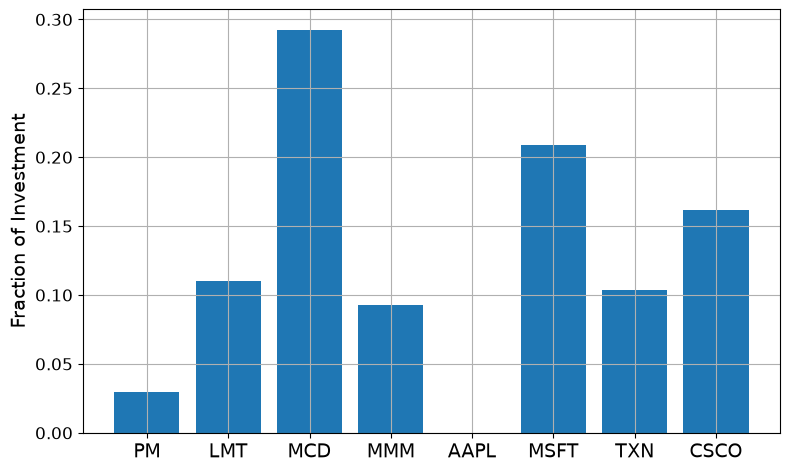

In [7]:
import matplotlib.pyplot as plt

plt.figure(figsize=(9, 5.5))
plt.bar(data.columns, x.get())
plt.ylabel('Fraction of Investment', fontsize=14)
plt.xticks(fontsize=14)
plt.yticks(fontsize=12)
plt.grid()
plt.show()

<br>
<br>

<font size="5">Reference</font>

```{bibliography}
:filter: docname in docnames
```